In [101]:
import seaborn as sns
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt


In [102]:
df = pd.read_csv("C:/Users/Mi/Desktop/heart-disease-prediction/data/heart_cleveland_upload_EDA.csv") 

In [ ]:
df

,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition,chol_log
0,0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0,5.459586
1,1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0,5.480639
2,2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0,5.424950
3,3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1,5.645447
4,4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0,5.356586
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,292,40,1,3,152,223,0,0,181,0,0.0,0,0,2,1,5.411646
293,293,39,1,3,118,219,0,0,140,0,1.2,1,0,2,1,5.393628
294,294,35,1,3,120,198,0,0,130,1,1.6,1,0,2,1,5.293305
295,295,35,0,3,138,183,0,0,182,0,1.4,0,0,0,0,5.214936


In [104]:
df = df.drop('Unnamed: 0', axis=1)

In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
 14  chol_log   297 non-null    float64
dtypes: float64(2), int64(13)
memory usage: 34.9 KB


In [106]:
# Те признаки у которых 1 2 3 и так далее не означают что 1 лучше чем 0 и так далее нужно привести в тип category, чтобы describe показал более полезную для них информацию
category_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'condition']

for col in category_cols:
    df[col] = df[col].astype('category')

df.describe(include='category')  # категориальные

,sex,cp,fbs,restecg,exang,slope,ca,thal,condition
count,297,297,297,297,297,297,297,297,297
unique,2,4,2,3,2,3,4,3,2
top,1,3,0,0,0,0,0,0,0
freq,201,142,254,147,200,139,174,164,160


# Feature engineering

## Блок 1. Создание новых признаков

In [ ]:
#Максимальный пульс человека = 220 - возраст, укажу это модели конкретно
df['max_hr_expected'] = 220 - df['age']
df['hr_reserve_ratio'] = df['thalach'] / df['max_hr_expected']
df[['max_hr_expected','hr_reserve_ratio', 'thalach']]

,max_hr_expected,hr_reserve_ratio,thalach
0,151,0.867550,131
1,151,1.000000,151
2,154,0.740260,114
3,155,1.122581,174
4,156,0.923077,144
...,...,...,...
292,180,1.005556,181
293,181,0.773481,140
294,185,0.702703,130
295,185,0.983784,182


In [108]:
df.drop('max_hr_expected', axis=1, inplace=True)

In [109]:
#Чем больше возраст тем опаснее высокий холестерин, укажим это в датасете
df['chol_per_age'] = df['chol'] / df['age']
df['chol_per_age']

0      3.391304
1      3.463768
2      3.424242
3      4.338462
4      3.296875
         ...   
292    5.575000
293    5.615385
294    5.657143
295    5.228571
296    8.057143
Name: chol_per_age, Length: 297, dtype: float64

In [110]:
#Есть ли дисперсия вообще, какая она это уже не так важно, само её наличие уже говорит о проблемах с сердцем
df['oldpeak_is_zero'] = (df['oldpeak'] == 0).astype(int)
df['oldpeak_is_zero']

0      0
1      0
2      0
3      0
4      0
      ..
292    1
293    0
294    0
295    0
296    1
Name: oldpeak_is_zero, Length: 297, dtype: int64

## Блок 2. Кодирование категориальных признаков

In [111]:
cat_cols = [i for i in list(df.columns) if df[i].dtype == "category" and i != 'condition']
cat_cols

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

In [112]:
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
df_encoded


,age,trestbps,chol,thalach,oldpeak,condition,chol_log,hr_reserve_ratio,chol_per_age,oldpeak_is_zero,...,restecg_1,restecg_2,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,thal_1,thal_2
0,69,160,234,131,0.1,0,5.459586,0.867550,3.391304,0,...,False,True,False,True,False,True,False,False,False,False
1,69,140,239,151,1.8,0,5.480639,1.000000,3.463768,0,...,False,False,False,False,False,False,True,False,False,False
2,66,150,226,114,2.6,0,5.424950,0.740260,3.424242,0,...,False,False,False,False,True,False,False,False,False,False
3,65,138,282,174,1.4,1,5.645447,1.122581,4.338462,0,...,False,True,False,True,False,True,False,False,False,False
4,64,110,211,144,1.8,0,5.356586,0.923077,3.296875,0,...,False,True,True,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,40,152,223,181,0.0,1,5.411646,1.005556,5.575000,1,...,False,False,False,False,False,False,False,False,False,True
293,39,118,219,140,1.2,1,5.393628,0.773481,5.615385,0,...,False,False,False,True,False,False,False,False,False,True
294,35,120,198,130,1.6,1,5.293305,0.702703,5.657143,0,...,False,False,True,True,False,False,False,False,False,True
295,35,138,183,182,1.4,0,5.214936,0.983784,5.228571,0,...,False,False,False,False,False,False,False,False,False,False


In [113]:
cols_corr = [i for i in df.columns if df[i].dtype in ['int64', 'float64']]
print(cols_corr)

cols_corr.append('condition')
corr = df[cols_corr].corr()


['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'chol_log', 'hr_reserve_ratio', 'chol_per_age', 'oldpeak_is_zero']


In [114]:
corr['condition'].sort_values() 

thalach            -0.423817
hr_reserve_ratio   -0.364995
oldpeak_is_zero    -0.264026
chol_per_age       -0.097791
chol                0.080285
chol_log            0.087161
trestbps            0.153490
age                 0.227075
oldpeak             0.424052
condition           1.000000
Name: condition, dtype: float64

In [115]:
df['condition'] = df['condition'].astype(int)

# Блок 3. Modeling

## Подготовка данных

In [116]:
X = df.drop('condition', axis=1)
y = df['condition'].astype(int)

In [117]:
print(X.shape)  # (297, N)
print(y.value_counts())  # баланс

(297, 17)
condition
0    160
1    137
Name: count, dtype: int64


In [118]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [119]:
print(f"Train: {X_train.shape[0]} строк")
print(f"Test: {X_test.shape[0]} строк")
print(f"Баланс train: {y_train.value_counts(normalize=True)}")
print(f"Баланс test: {y_test.value_counts(normalize=True)}")

Train: 237 строк
Test: 60 строк
Баланс train: condition
0    0.540084
1    0.459916
Name: proportion, dtype: float64
Баланс test: condition
0    0.533333
1    0.466667
Name: proportion, dtype: float64


## Baseline

In [120]:
from sklearn.metrics import accuracy_score
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_dummy):.3f}")

Accuracy: 0.533


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
y_proba_lr = lr_pipe.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.3f}")
print(f"AUC: {roc_auc_score(y_test, y_proba_lr):.3f}")

Accuracy: 0.883
AUC: 0.959


## Catboost

In [ ]:
from catboost import CatBoostClassifier

cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    cat_features=cat_features,
    random_seed=42,
    verbose=100,  # печатает метрику каждые 100 итераций
    auto_class_weights='Balanced'
)

model.fit(X_train, y_train)

0:	learn: 0.6588735	total: 46.8ms	remaining: 23.4s


100:	learn: 0.1697693	total: 5.08s	remaining: 20.1s
200:	learn: 0.0827444	total: 12.1s	remaining: 18s
300:	learn: 0.0459214	total: 17.6s	remaining: 11.7s
400:	learn: 0.0296879	total: 23.1s	remaining: 5.71s
499:	learn: 0.0209613	total: 28.2s	remaining: 0us


CatBoostClassifier(auto_class_weights='Balanced', cat_features=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'], depth=6, iterations=500, learning_rate=0.05, random_seed=42, verbose=100)

In [123]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_scores = cross_val_score(lr_pipe, X_train, y_train, cv=cv_split, scoring='roc_auc')

print(f"LR CV AUC: {lr_scores.mean():.3f} ± {lr_scores.std():.3f}")

LR CV AUC: 0.887 ± 0.039


In [124]:
from catboost import cv, Pool

# Создаёшь Pool (он знает про категории)
train_pool = Pool(X_train, y_train, cat_features=cat_features)
    
# Параметры модели (словарь, не объект)
params = {
    'iterations': 150,       # было 500, стало 150 (по bestIteration)
    'depth': 4,              # было 6, стало 4 (проще деревья)
    'learning_rate': 0.1,    # было 0.05, стало 0.1 (быстрее сходится)
    'l2_leaf_reg': 5,        # регуляризация (было 3 по умолчанию)
    'random_seed': 42,
    'verbose': 0,
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',
    'auto_class_weights': 'Balanced'
}

# Запускаешь CV
cv_results = cv(
    pool=train_pool,
    params=params,
    fold_count=5,
    stratified=True,
    shuffle=True,
    seed=42
)
# результат
print(f"CB AUC: {cv_results['test-AUC-mean'].iloc[-1]:.3f} "
      f"± {cv_results['test-AUC-std'].iloc[-1]:.3f}")

Training on fold [0/5]

bestTest = 0.9458041958
bestIteration = 99

Training on fold [1/5]

bestTest = 0.951048951
bestIteration = 16

Training on fold [2/5]

bestTest = 0.8444055944
bestIteration = 40

Training on fold [3/5]

bestTest = 0.8818181818
bestIteration = 18

Training on fold [4/5]

bestTest = 0.8666666667
bestIteration = 51

CB AUC: 0.881 ± 0.051


## RF

In [125]:
X_encoded = df_encoded.drop('condition', axis=1)
y_encoded = df_encoded['condition'].astype(int)

In [126]:
from sklearn.model_selection import train_test_split
X_train_encoded, X_test_encoded, y_train_encoded, y_test_encoded = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y
)

In [127]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold


rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf_scores = cross_val_score(rf, X_train_encoded, y_train, cv=cv_split, scoring='roc_auc')
print(f"RF CV AUC: {rf_scores.mean():.3f} ± {rf_scores.std():.3f}")

RF CV AUC: 0.864 ± 0.050


## Финальная модель

In [ ]:
final_model = CatBoostClassifier(
    iterations=150, depth=4, learning_rate=0.1,
    l2_leaf_reg=5, cat_features=cat_features,
    random_seed=42, verbose=0, auto_class_weights='Balanced'
)
final_model.fit(X_train, y_train)

# Оцени на test
y_proba_test = final_model.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Test Accuracy: {accuracy_score(y_test, final_model.predict(X_test)):.3f}")

Test AUC: 0.942
Test Accuracy: 0.833


In [129]:
importance = final_model.get_feature_importance()
feature_names = X_train.columns

imp_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importance
}).sort_values('importance', ascending=False)

print(imp_df)

             feature  importance
2                 cp   18.376052
11                ca   17.115312
9            oldpeak   14.220699
12              thal   11.709572
14  hr_reserve_ratio    6.903508
0                age    5.645924
10             slope    5.358238
15      chol_per_age    4.227532
8              exang    3.572483
13          chol_log    3.007408
7            thalach    2.765628
4               chol    2.567564
1                sex    1.972906
3           trestbps    1.854573
16   oldpeak_is_zero    0.538583
5                fbs    0.164017
6            restecg    0.000000


## Shap

In [130]:
import shap

# TreeExplainer — быстрый, точный, для деревьев (CatBoost, RF, XGBoost)
explainer = shap.TreeExplainer(final_model)

# SHAP-значения для всех пациентов (или выборки)
shap_values = explainer.shap_values(X_train)

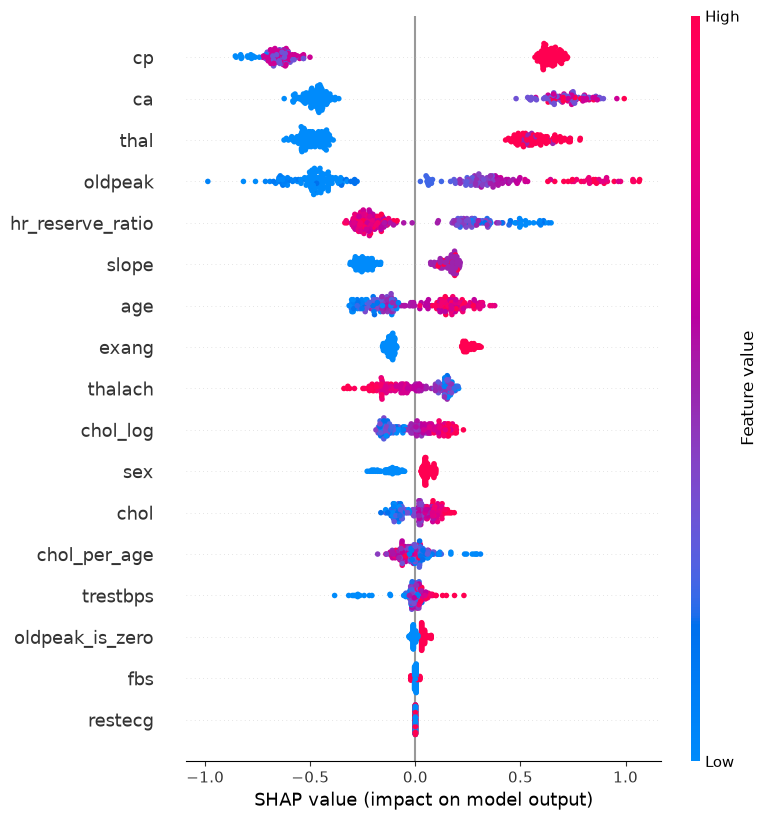

In [131]:
X_train_numeric = X_train.copy()
for col in cat_features:
    X_train_numeric[col] = X_train_numeric[col].astype(int)

shap.summary_plot(shap_values, X_train_numeric)

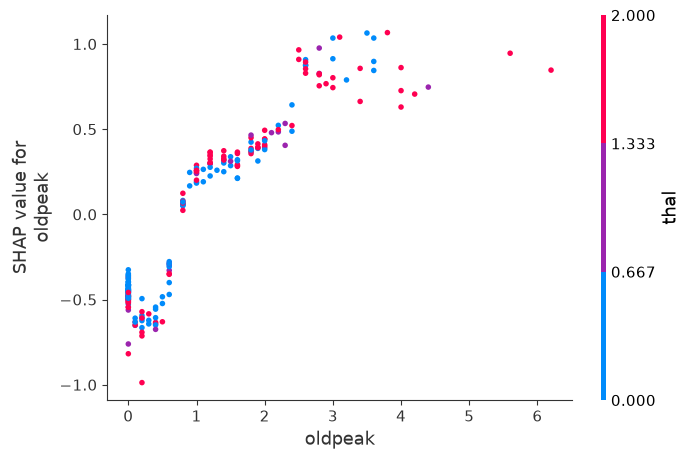

In [132]:
shap.dependence_plot('oldpeak', shap_values, X_train)

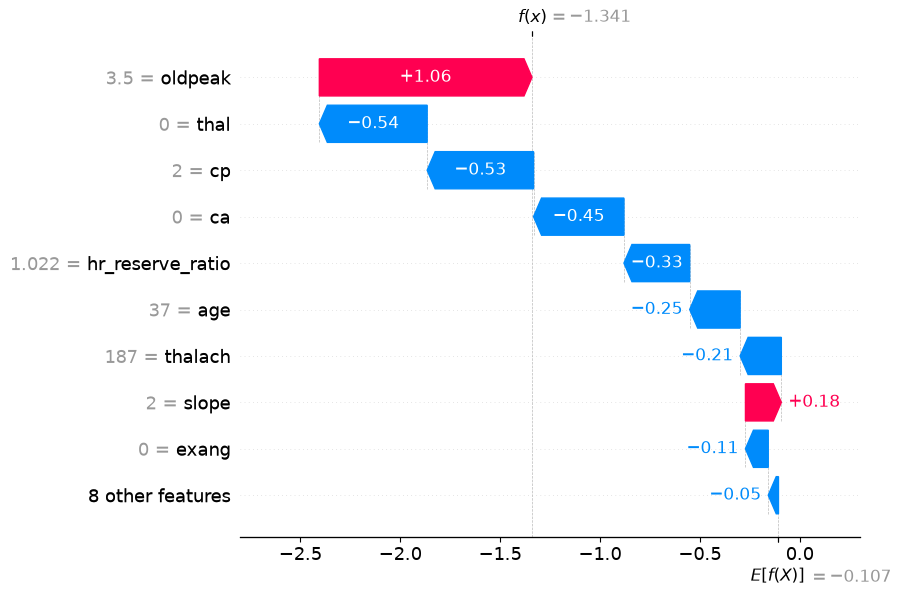

Вероятность: 0.207


In [133]:
# Пациент №20 из train
patient_idx = 20
explanation = shap.Explanation(
    values=shap_values[patient_idx],
    base_values=explainer.expected_value,   
    data=X_train.iloc[patient_idx].values,
    feature_names=X_train.columns
)

shap.plots.waterfall(explanation)

patient = X_train.iloc[[patient_idx]]  # двойные скобки → DataFrame

proba = final_model.predict_proba(patient)[:, 1][0]
print(f"Вероятность: {proba:.3f}")

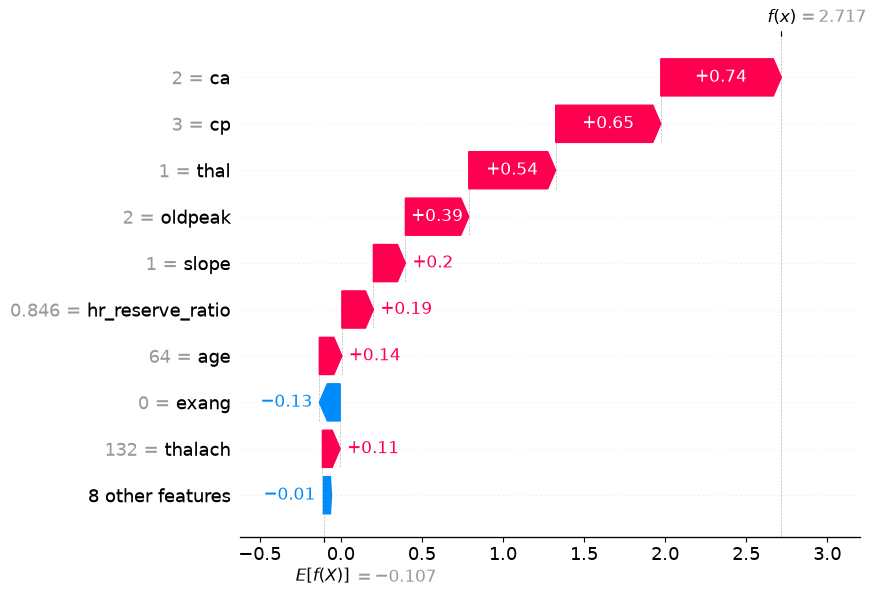

Вероятность: 0.938


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,chol_log,hr_reserve_ratio,chol_per_age,oldpeak_is_zero
175,64,1,3,145,212,0,2,132,0,2.0,1,2,1,5.361292,0.846154,3.3125,0


In [141]:
# Пациент №6 из train
patient_idx = 6
explanation = shap.Explanation(
    values=shap_values[patient_idx],
    base_values=explainer.expected_value,   
    data=X_train.iloc[patient_idx].values,
    feature_names=X_train.columns
)

shap.plots.waterfall(explanation)

patient = X_train.iloc[[patient_idx]]  # двойные скобки → DataFrame

proba = final_model.predict_proba(patient)[:, 1][0]
print(f"Вероятность: {proba:.3f}")
X_train.iloc[[patient_idx]]

In [135]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_test = final_model.predict(X_test)
print(classification_report(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.81      0.91      0.85        32
           1       0.88      0.75      0.81        28

    accuracy                           0.83        60
   macro avg       0.84      0.83      0.83        60
weighted avg       0.84      0.83      0.83        60

[[29  3]
 [ 7 21]]


In [136]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
# --- Порог 0.4 ---
y_pred_04 = (y_proba_test >= 0.4).astype(int)

print("\n=== Порог 0.4 ===")
print(classification_report(y_test, y_pred_04))
print(confusion_matrix(y_test, y_pred_04))

# --- Сравнение ---
print(f"AUC не меняется (не зависит от порога): {roc_auc_score(y_test, y_proba_test):.3f}")


=== Порог 0.4 ===
              precision    recall  f1-score   support

           0       0.88      0.91      0.89        32
           1       0.89      0.86      0.87        28

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60

[[29  3]
 [ 4 24]]
AUC не меняется (не зависит от порога): 0.942


In [137]:
# Сохранение
final_model.save_model(
    "C:/Users/Mi/Desktop/heart-disease-prediction/models/catboost_model.cbm",
    format="cbm",                          # CatBoost binary format
    export_parameters=None,
    pool=None
)

In [138]:
import json

model_metadata = {
    'model_name': 'heart_disease_catboost',
    'model_version': '1.0',
    'threshold': 0.40,
    'class_labels': {'0': 'здоров', '1': 'болезнь сердца'},
    'cat_features': ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'],
    'feature_names': list(X_train.columns),
    'cv_auc': 0.881,
    'test_auc': 0.942
}

with open('../models/model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(model_metadata, f, indent=2)

In [139]:
from catboost import CatBoostClassifier

loaded_model = CatBoostClassifier()
loaded_model.load_model("C:/Users/Mi/Desktop/heart-disease-prediction/models/catboost_model.cbm")

# Проверка
y_proba = loaded_model.predict_proba(X_test)[:, 1]
y_proba

array([0.13992262, 0.57292199, 0.10205284, 0.25782935, 0.04715549,
       0.26389446, 0.83200132, 0.54368284, 0.4841452 , 0.03276654,
       0.91166555, 0.36157369, 0.10888899, 0.89731936, 0.44036081,
       0.25605458, 0.21740947, 0.26180127, 0.74570811, 0.858672  ,
       0.12287567, 0.23645522, 0.44521199, 0.09189597, 0.96968755,
       0.3284429 , 0.09131832, 0.65463214, 0.34220348, 0.96960588,
       0.29065773, 0.89065595, 0.85134311, 0.27089416, 0.3013873 ,
       0.95116555, 0.04311787, 0.94621411, 0.1364423 , 0.96773956,
       0.03671778, 0.96580032, 0.51680723, 0.92086138, 0.10416646,
       0.05544036, 0.75533494, 0.10524373, 0.31869662, 0.19141332,
       0.5056617 , 0.97072015, 0.04240567, 0.09670738, 0.87934691,
       0.82508326, 0.31405104, 0.03462177, 0.35953545, 0.9760707 ])

In [140]:
df.to_csv("C:/Users/Mi/Desktop/heart-disease-prediction/data/heart_cleveland_upload_FE.csv") 